# Missing Data: Why It's Missing Matters More Than How Much
### CIS*4020 Assignment 3: Tutorial Notebook, Luc Levesque

> **Scaffold note (delete before submitting):** every `TODO` cell is a prompt for prose you write in your own words.
> The code cells are complete and run top to bottom. Read and understand each one, since you have to be able to explain every line.

## 1. Overview
TODO (one paragraph): what the reader will learn and what they should already know.
- Learn: the three missingness mechanisms (MCAR, MAR, MNAR), how each one biases a naive analysis, and which imputation strategies do or don't fix it.
- Prerequisites: pandas, scikit-learn's fit/transform API, linear regression, mean/standard deviation.
- Time: about 25 minutes.

## 2. Motivation
TODO: lead with intuition before any definitions. A suggested analogy:
- A professor sends an optional survey asking students for their exam score. 30% don't answer.
  - If the non-answers are random (the email went to spam), the average of the answers is fine.
  - If students who studied less were less likely to answer, the average is too high, **but** we can see study hours, so we can correct for it.
  - If students who *did badly* didn't want to share their score, the average is too high and the data alone can't tell you.
- Point: the *same* 30% missing can be harmless or badly misleading depending on **why** values are missing.
- When you'd use this: any real dataset (you saw 1,111 `"?"` values in OULAD's `imd_band` in A1).

## 3. The concept
TODO: define the terms as you introduce them. Suggested order:
1. **Missingness indicator** $R$: $R_i = 1$ if the value is missing for row $i$. The mechanism is a statement about what $P(R = 1)$ depends on.
2. Split the data into the observed part $Y_{obs}$ and the missing part $Y_{mis}$.
3. **MCAR** (Missing Completely At Random): $P(R=1 \mid Y_{obs}, Y_{mis}) = P(R=1)$. Missingness depends on nothing.
4. **MAR** (Missing At Random): $P(R=1 \mid Y_{obs}, Y_{mis}) = P(R=1 \mid Y_{obs})$. It depends only on things you *can see*. Flag that the name is misleading: MAR is not "random".
5. **MNAR** (Missing Not At Random): it depends on the missing value itself (or something unobserved).
6. Explain each part of the notation in words, not just the formula.
7. Imputation strategies covered: listwise deletion, mean imputation, k-NN imputation, regression-based (iterative) imputation, and stochastic regression imputation. One sentence each on the idea.

## 4. Worked example
### 4.1 Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.experimental import enable_iterative_imputer  # noqa: F401  (unlocks IterativeImputer)
from sklearn.impute import SimpleImputer, KNNImputer, IterativeImputer
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

SEED = 4020
rng = np.random.default_rng(SEED)
pd.set_option("display.precision", 2)

### 4.2 A complete dataset we control
TODO: explain why we use simulated data. We know the *true* answer, so we can measure exactly how wrong each method is. On real data you never get to see the values that are missing.

In [2]:
N = 2000
study_hours = rng.gamma(shape=4, scale=2.5, size=N)          # weekly hours, mean about 10
prior_gpa = np.clip(rng.normal(2.9, 0.5, size=N), 0, 4)
exam_score = 30 + 1.8 * study_hours + 7 * prior_gpa + rng.normal(0, 8, size=N)
exam_score = np.clip(exam_score, 0, 100)

full = pd.DataFrame({"study_hours": study_hours,
                     "prior_gpa": prior_gpa,
                     "exam_score": exam_score})
COLS = list(full.columns)
full.describe()

,study_hours,prior_gpa,exam_score
count,2000.00,2000.00,2000.00
mean,9.91,2.90,68.07
std,5.08,0.49,12.10
min,0.98,1.01,29.11
25%,6.26,2.56,59.81
50%,9.14,2.91,67.14
75%,12.73,3.24,76.19
max,38.38,4.00,100.00


### 4.3 Simulating the three mechanisms
We remove about 30% of `exam_score` three different ways. Only *what drives the missingness* changes between them.

TODO: walk through `missing_mask`. It turns a "driver" column into a probability of being missing with a logistic curve, then tunes the intercept so the overall rate is 30%. A negative `strength` means low values of the driver go missing more often.

In [3]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))


def missing_mask(driver, strength, rate, rng):
    """Boolean mask, True = missing. P(missing) is logistic in the standardized driver."""
    z = (driver - driver.mean()) / driver.std()
    lo, hi = -10.0, 10.0
    for _ in range(60):                                       # bisection on the intercept
        b0 = (lo + hi) / 2
        if sigmoid(b0 + strength * z).mean() < rate:
            lo = b0
        else:
            hi = b0
    return rng.random(len(driver)) < sigmoid(b0 + strength * z)


def make_missing(df, mechanism, rate=0.30, strength=-2.0, rng=rng):
    out = df.copy()
    if mechanism == "MCAR":
        mask = rng.random(len(df)) < rate                     # depends on nothing
    elif mechanism == "MAR":
        mask = missing_mask(df["study_hours"], strength, rate, rng)   # depends on an OBSERVED column
    elif mechanism == "MNAR":
        mask = missing_mask(df["exam_score"], strength, rate, rng)    # depends on the value ITSELF
    else:
        raise ValueError(mechanism)
    out.loc[mask, "exam_score"] = np.nan
    return out


MECHS = ["MCAR", "MAR", "MNAR"]
datasets = {m: make_missing(full, m) for m in MECHS}
pd.Series({m: d["exam_score"].isna().mean() for m, d in datasets.items()}, name="fraction missing")

MCAR    0.30
MAR     0.32
MNAR    0.29
Name: fraction missing, dtype: float64

### 4.4 What does the missingness look like?

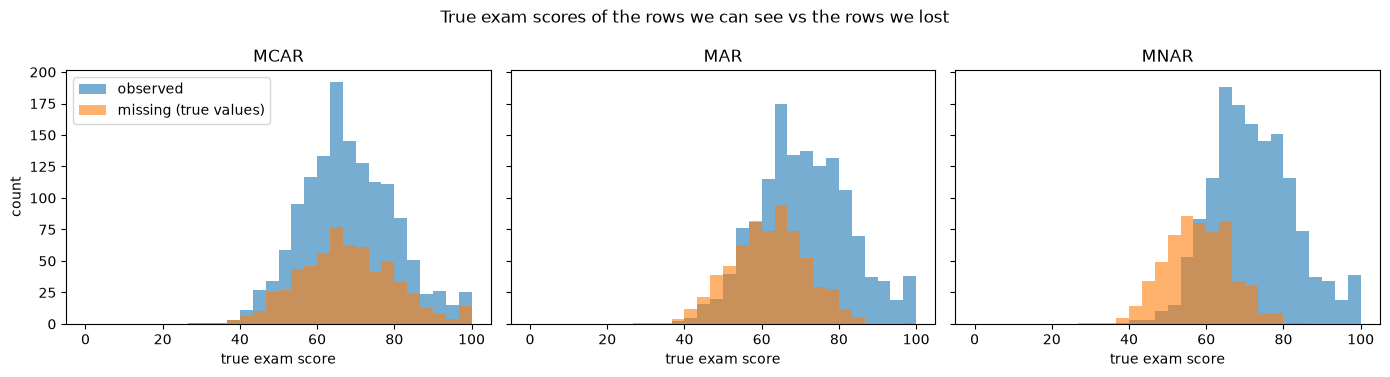

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
bins = np.linspace(0, 100, 31)
for ax, m in zip(axes, MECHS):
    is_missing = datasets[m]["exam_score"].isna()
    ax.hist(full.loc[~is_missing, "exam_score"], bins=bins, alpha=0.6, label="observed")
    ax.hist(full.loc[is_missing, "exam_score"], bins=bins, alpha=0.6, label="missing (true values)")
    ax.set_title(m)
    ax.set_xlabel("true exam score")
axes[0].set_ylabel("count")
axes[0].legend()
plt.suptitle("True exam scores of the rows we can see vs the rows we lost")
plt.tight_layout()
plt.show()

TODO: interpret ("notice that..."). Under MCAR the two histograms have the same shape. Under MAR and MNAR the missing rows are shifted toward low scores, so the observed rows over-represent strong students.

In [5]:
naive = pd.DataFrame({
    "true mean": full["exam_score"].mean(),
    "mean of observed": {m: d["exam_score"].mean() for m, d in datasets.items()},
})
naive["bias"] = naive["mean of observed"] - naive["true mean"]
naive

,true mean,mean of observed,bias
MCAR,68.07,68.17,0.09
MAR,68.07,70.98,2.91
MNAR,68.07,72.20,4.13


TODO: interpret the bias column. Only MCAR gives an unbiased average from the complete cases.

### 4.5 Can we tell the mechanisms apart from the data?
A common diagnostic: compare the *observed* columns between rows with and without a missing score.

In [6]:
diag = pd.DataFrame({
    m: d.groupby(d["exam_score"].isna())["study_hours"].mean()
    for m, d in datasets.items()
}).T
diag.columns = ["study_hours | score observed", "study_hours | score missing"]
diag

,study_hours | score observed,study_hours | score missing
MCAR,9.88,9.97
MAR,11.61,6.26
MNAR,11.01,7.19


TODO: interpret. MCAR shows no difference, so this check can rule MCAR *out*. But MAR and MNAR **both** show a difference (in MNAR because study hours are correlated with the score). The observed data can't distinguish MAR from MNAR. That assumption comes from domain knowledge, not from a test.

### 4.6 Imputation strategies
TODO: introduce each method in a sentence before the code. We judge each one on three things a real analysis would report: the **mean** score, the **spread** (standard deviation), and the **slope** of score on study hours from a regression. "Truth" is each one computed on the complete data. (The slope is about 1.67 rather than the 1.8 we simulated, because clipping scores at 100 flattens the top end.)

In [7]:
def impute(df, method, cols=COLS, seed=SEED):
    """Return a DataFrame with exam_score filled in (or rows dropped for listwise)."""
    X = df[cols]
    if method == "listwise":
        return X.dropna()
    if method == "mean":
        filled = SimpleImputer(strategy="mean").fit_transform(X)
    elif method == "knn":
        scaler = StandardScaler().fit(X)                       # k-NN uses distances, so scale first
        filled = scaler.inverse_transform(KNNImputer(n_neighbors=10).fit_transform(scaler.transform(X)))
    elif method == "regression":
        filled = IterativeImputer(random_state=seed).fit_transform(X)
    elif method == "stochastic":
        filled = IterativeImputer(sample_posterior=True, random_state=seed).fit_transform(X)
    else:
        raise ValueError(method)
    return pd.DataFrame(filled, columns=cols, index=X.index)


def summarize(d):
    slope = LinearRegression().fit(d[["study_hours", "prior_gpa"]], d["exam_score"]).coef_[0]
    return {"mean": d["exam_score"].mean(), "std": d["exam_score"].std(), "slope_hours": slope}


METHODS = ["listwise", "mean", "knn", "regression", "stochastic"]
truth = summarize(full)

rows = []
for m in MECHS:
    for meth in METHODS:
        rows.append({"mechanism": m, "method": meth, **summarize(impute(datasets[m], meth))})
results = pd.DataFrame(rows).set_index(["mechanism", "method"])

print("Truth:", {k: round(v, 2) for k, v in truth.items()})
results

Truth: {'mean': np.float64(68.07), 'std': np.float64(12.1), 'slope_hours': np.float64(1.67)}


mean    std  slope_hours
mechanism method                               
MCAR      listwise    68.17  12.02         1.66
          mean        68.17  10.04         1.14
          knn         68.15  11.24         1.63
          regression  68.19  11.26         1.66
          stochastic  68.28  12.12         1.67
MAR       listwise    70.98  11.97         1.65
          mean        70.98   9.88         1.11
          knn         68.10  11.24         1.66
          regression  68.12  11.11         1.65
          stochastic  68.23  12.02         1.64
MNAR      listwise    72.20  10.82         1.44
          mean        72.20   9.12         1.08
          knn         70.40  10.00         1.43
          regression  70.36  10.00         1.44
          stochastic  70.35  10.72         1.42

In [8]:
bias = results - pd.Series(truth)
bias.round(2)          # estimate minus truth; 0 = perfect

mean   std  slope_hours
mechanism method                             
MCAR      listwise    0.09 -0.08        -0.00
          mean        0.09 -2.06        -0.53
          knn         0.08 -0.86        -0.04
          regression  0.11 -0.84        -0.00
          stochastic  0.20  0.02         0.00
MAR       listwise    2.91 -0.13        -0.02
          mean        2.91 -2.22        -0.55
          knn         0.03 -0.86        -0.01
          regression  0.05 -0.99        -0.02
          stochastic  0.15 -0.08        -0.03
MNAR      listwise    4.13 -1.28        -0.23
          mean        4.13 -2.98        -0.59
          knn         2.33 -2.10        -0.24
          regression  2.29 -2.10        -0.23
          stochastic  2.27 -1.38        -0.25

TODO: this is the core interpretation. Walk the reader through the table one mechanism at a time:
- **MCAR:** listwise deletion is unbiased (it just loses rows). Mean imputation keeps the mean but **shrinks the std** and **flattens the slope**, because every filled-in row sits at the average and has no relationship to study hours.
- **MAR:** listwise deletion now biases the mean upward. But its slope is still about right, because missingness depends only on a predictor in the regression. Regression/iterative and k-NN use `study_hours` to fill in, so they recover the mean.
- **Regression vs stochastic:** deterministic regression imputation puts every filled value exactly on the regression line, so the std is slightly too small. Adding noise (`sample_posterior=True`) restores it.
- **MNAR:** every method is biased, because the information needed to fix it was never observed.
- Check the numbers against the table after you run it.

## 5. Common pitfalls & misconceptions
TODO (worth 10 pts, so write these with care and add your own). Candidates, each with a short "how to avoid":
1. **"MAR means random."** It doesn't. MAR missingness can be strongly systematic. It just has to be explainable by observed columns.
2. **"Mean imputation is a safe default."** It keeps the mean only under MCAR, and it always shrinks variance and weakens correlations (section 4.6).
3. **"You can test for MAR."** You can reject MCAR (section 4.5), but MAR vs MNAR is untestable from the data alone.
4. **MAR is relative to what you give the imputer.** If you leave the driver of missingness out of the imputation model, MAR effectively becomes MNAR (see the exercise).
5. **Imputing before the train/test split** leaks test-set information. Fit the imputer on training data only, inside a `Pipeline`. This connects to your A2 leakage discussion.
6. **Imputing the target** for a supervised model, or throwing away the fact that a value was missing. Consider `SimpleImputer(add_indicator=True)`, since missingness itself can be predictive.
7. **Treating single imputation as if it were real data.** Standard errors come out too small. Multiple imputation addresses this (mention it, don't implement it).

## 6. Your turn
A colleague's dataset has missing exam scores, and this time the students with **lower prior GPA** are less likely to report.

1. Create the dataset with the helper below (missingness driven by `prior_gpa`).
2. Compare `listwise`, `mean`, and `regression` imputation on the **mean** exam score.
3. Now run `regression` imputation again, but give the imputer only `["study_hours", "exam_score"]` (leave `prior_gpa` out). What happens to the bias, and why?

TODO: tweak the wording, and give a hint about the `cols` argument of `impute`.

In [9]:
ex_rng = np.random.default_rng(SEED + 1)
exercise = full.copy()
exercise.loc[missing_mask(full["prior_gpa"], -2.0, 0.30, ex_rng), "exam_score"] = np.nan

# Your code here

### Solution (try the exercise first!)

In [10]:
ex_rows = {meth: summarize(impute(exercise, meth))["mean"] for meth in ["listwise", "mean", "regression"]}
ex_rows["regression, prior_gpa left out"] = impute(exercise, "regression",
                                                   cols=["study_hours", "exam_score"])["exam_score"].mean()
ex = pd.Series(ex_rows, name="estimated mean").to_frame()
ex["bias"] = ex["estimated mean"] - full["exam_score"].mean()
ex

,estimated mean,bias
listwise,69.48,1.41
mean,69.48,1.41
regression,68.16,0.08
"regression, prior_gpa left out",69.29,1.22


TODO: explain the solution. With `prior_gpa` included, the data are MAR and regression imputation removes most of the bias. Leave it out, and from the imputer's point of view the missingness depends on something it can't see. `study_hours` carries almost no information about GPA, so most of the bias comes back (about +1.2 vs +0.1). Same data, same method: the only change is which columns the imputer can see. That's pitfall 4.

## 7. Key takeaways
TODO: 3–5 bullets, for example:
- Why data are missing matters more than how much is missing.
- Complete-case analysis is only safe for means under MCAR.
- Under MAR, conditional imputation that uses the right observed columns removes the bias. Mean imputation does not.
- MNAR can't be fixed or detected from the data alone. Use domain knowledge and sensitivity analysis.
- Fit imputers on training data only, and think about keeping a missingness indicator.

## 8. References
TODO: check each one and format consistently (APA or IEEE).
- Rubin, D. B. (1976). Inference and missing data. *Biometrika*, 63(3), 581–592.
- Little, R. J. A., & Rubin, D. B. (2019). *Statistical Analysis with Missing Data* (3rd ed.). Wiley.
- van Buuren, S. (2018). *Flexible Imputation of Missing Data* (2nd ed.). CRC Press. https://stefvanbuuren.name/fimd/
- scikit-learn developers. Imputation of missing values. scikit-learn User Guide. https://scikit-learn.org/stable/modules/impute.html

## Generative-AI disclosure
TODO: describe how you used AI, for example: "I used Claude (Anthropic) to choose the topic and to generate an initial scaffold of this notebook: section structure, simulation code and imputation comparison code. I rewrote all explanations in my own words, checked every result against the output, and ..."